# Experimentos

Se corren experimentos con diferentes distribuciones 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
# import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

from numpy import random
from collections import Counter
from importlib import reload

import agentes_clase as A

from collections import defaultdict

In [2]:
reload(A)

<module 'agentes_clase' from '/home/sergio/trabajo/phd/modelo_gentrificacion/agentes_clase.py'>

## Agentes

Vamos a crear agentes pero con una distribución de salario con distribución exponencial es decir la variable $S$ debe ser muestreado de una distribución exponencial
$$
S \sim \operatorname{Exp}(\lambda)
$$

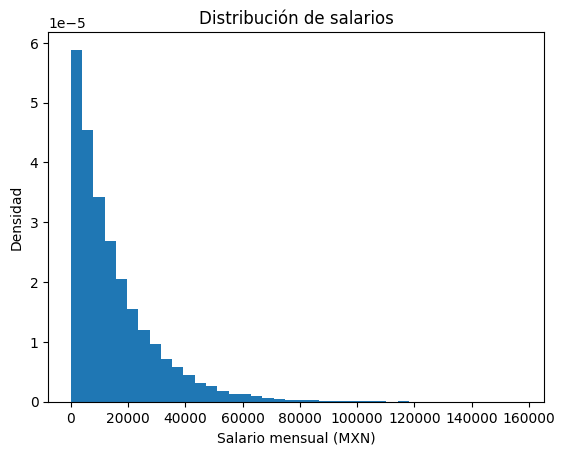

In [3]:
rng = np.random.default_rng(42)

N =  39_000           # Número de individuos
mu = 15000            # Salario promedio mensual (MXN)

salarios = rng.exponential(scale=mu, size=N)

plt.hist(salarios, bins=40, density=True)
plt.xlabel("Salario mensual (MXN)")
plt.ylabel("Densidad")
plt.title("Distribución de salarios")
plt.show()

In [4]:
np.random.shuffle(salarios)
salarios[0]

np.float64(493.18034831367106)

In [5]:
# salarios = [np.random.normal(5,1) for _ in range(1000)]
# salarios = np.clip(salarios, 0, max(salarios))
# len(salarios), min(salarios), max(salarios)

agentes = []
np.random.shuffle(salarios)

for j in range(N):
    agente = A.Agente() # direccion requerida dummy
    sal = salarios[j]
    agente.salario = sal
    agentes.append(agente)

Creamos los agentes a partir del método que genera salarios con una distribución exponencial

In [6]:
# creamos los agentes con un método
# requiere del rng para generar números aleatorios
#
agentes = A.crea_agentes_exponencial(rng, N=N)
print(f"Generando {N} agentes {len(agentes)}")

Generando 39000 agentes 39000


Ancho de banda 188


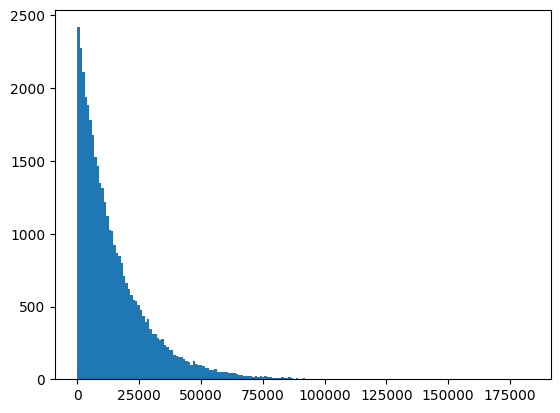

In [7]:
# comprobación de la distribución
salarios = np.array([ag.salario for ag in agentes])
bns = A.Obs.fd_bins(salarios)
print(f"Ancho de banda {bns}")
plt.hist(salarios, bins=bns);

## Vecindarios

Vamos a generar un vecindario con una distribución exponencial para los valores de la renta 

In [8]:
reload(A)

<module 'agentes_clase' from '/home/sergio/trabajo/phd/modelo_gentrificacion/agentes_clase.py'>

In [9]:
n = 50
params = {'tipo' : 'power_law', 'mu' : mu}

In [10]:
agentes = A.crea_agentes_exponencial(rng, N=2_500)

In [11]:
V = A.Vecindario(n=n,
                 k= 4, 
                 P=agentes,             # agentes recién creados
                 params=params, 
                 a = 0.1, 
                 b = 0.2,
                 pad=2)

Vamos a alojar a 2500 agentes


(array([1532.,  505.,  265.,   90.,   64.,   19.,   13.,    6.,    2.,
           4.]),
 array([     0.        ,  11767.62062535,  23535.2412507 ,  35302.86187605,
         47070.4825014 ,  58838.10312675,  70605.7237521 ,  82373.34437746,
         94140.96500281, 105908.58562816, 117676.20625351]),
 <BarContainer object of 10 artists>)

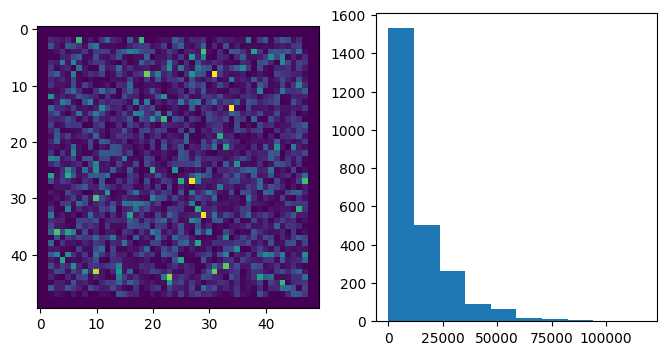

In [12]:
fig,ax = plt.subplots(1,2, figsize=(8,4))
ax[0].imshow(V.V)
ax[1].hist(V.V.flatten())

In [13]:
V.itera()

Las poblaciones C 1256 e I 1244


## Experimentos

In [18]:
reload(A)

<module 'agentes_clase' from '/home/sergio/trabajo/phd/modelo_gentrificacion/agentes_clase.py'>

### uno: ciudad pequeña

```
iteraciones = 50
a           = 0.1
b           = 0.2
mu          = 10
N           = 255
n           = 10
pad         = 1
```

¿Qué estamos poniendo en V?

In [50]:
V, obs, bins_e = A.experimento_exponencial(rng, iters=50, p=5, n=10, pad=1, N=255, mu=10)

Creando 255 agentes con distribución exponencial con parámetro 10 
Generando vecindario de (10x10) capacidad de carga 4 y 255 agentes
Vamos a alojar a 255 agentes
Corriendo las 50 iteraciones
Iteracion 5
Iteracion 10
Iteracion 15
Iteracion 20
Iteracion 25
Iteracion 30
Iteracion 35
Iteracion 40
Iteracion 45
--> Iteracion 50 <--


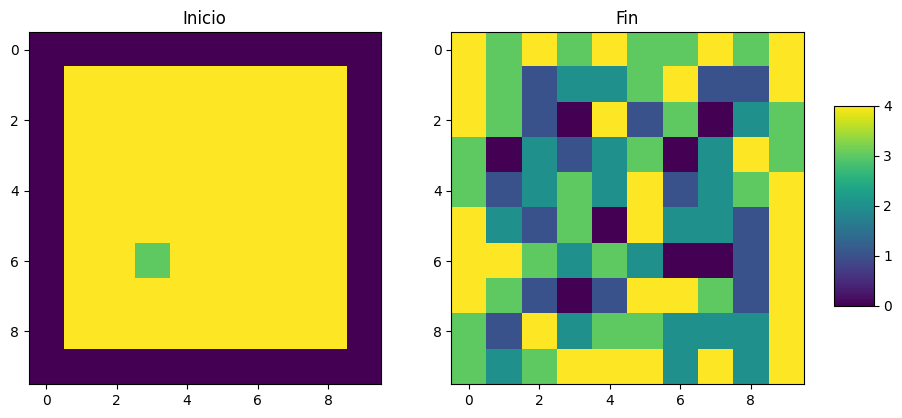

In [49]:
fig, ax = plt.subplots(1,2, figsize=(10,5))
cax = fig.add_axes([0.93, 0.3, 0.04, 0.4])

ax[0].set_title("Inicio")
im0 = ax[0].imshow(V[0], cmap='viridis')
ax[1].set_title("Fin")
im1 = ax[1].imshow(V[-1], cmap='viridis')

fig.colorbar(im1, cax=cax, orientation='vertical')
plt.show()

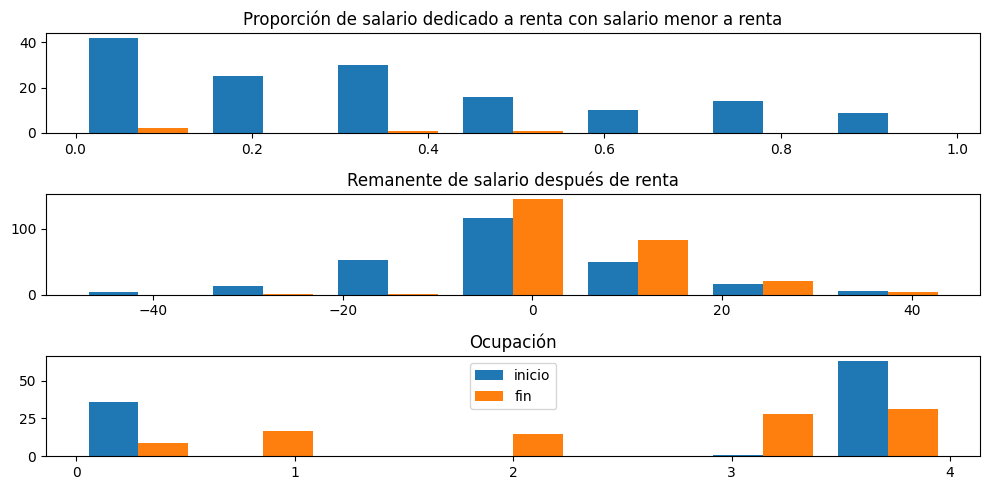

In [51]:
H = obs['estres']
E = obs['remanente']
O = obs['ocupacion']

fig, ax = plt.subplots(3,1, figsize=(10,5))

# al inicio

ax[0].hist((H[0],H[-1]),  label=['inicio','fin'], bins=bins_e);
ax[0].set_title('Proporción de salario dedicado a renta con salario menor a renta')
ax[1].hist((E[0],E[-1]), label=['inicio','fin'], bins=bins_e)
ax[1].set_title('Remanente de salario después de renta')
ax[2].hist((O[0],O[-1]), label=['inicio','fin'], bins=bins_e)
ax[2].set_xticks([0,1,2,3,4])
ax[2].set_title('Ocupación')

plt.legend()
plt.tight_layout()

### dos: n más pequeño 

```
iteraciones = 100
n           = 50
N           = 8_400
```

In [31]:
V, obs, bins_e = A.experimento_exponencial(rng, iters=100, n=50, N=8_400)

Creando 8400 agentes con distribución exponencial con parámetro 1000 
Generando vecindario de (50x50) capacidad de carga 4 y 8400 agentes
Vamos a alojar a 8400 agentes
Corriendo las 100 iteraciones
Iteracion 50
--> Iteracion 100 <--


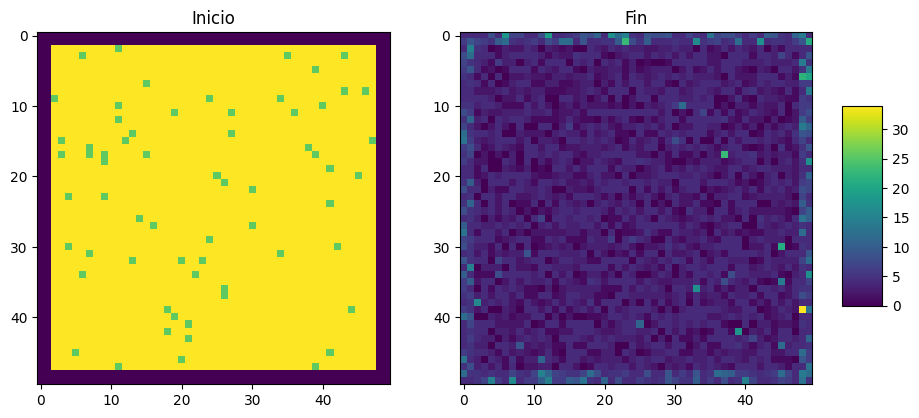

In [32]:
fig, ax = plt.subplots(1,2, figsize=(10,5))
cax = fig.add_axes([0.93, 0.3, 0.04, 0.4])

ax[0].set_title("Inicio")
im0 = ax[0].imshow(V[0], cmap='viridis')
ax[1].set_title("Fin")
im1 = ax[1].imshow(V[-1], cmap='viridis')

fig.colorbar(im1, cax=cax, orientation='vertical')
plt.show()

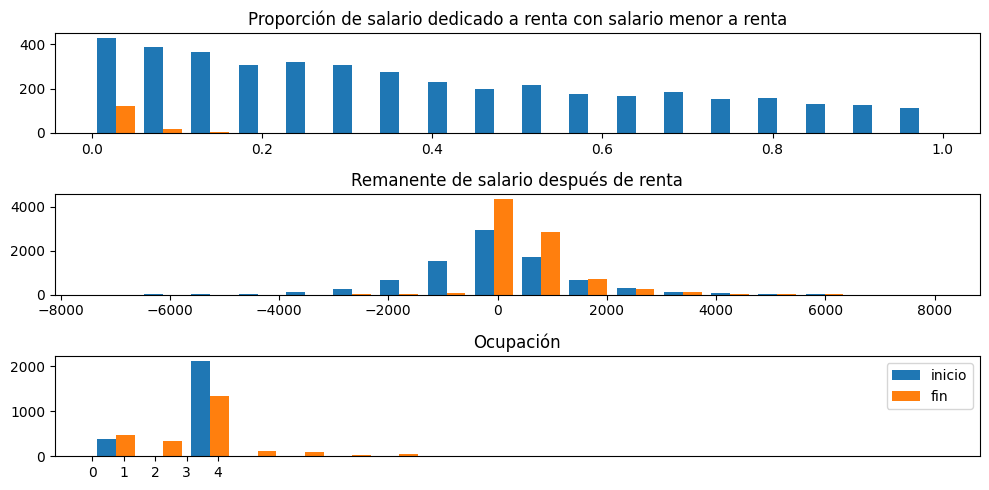

In [38]:
H = obs['estres']
E = obs['remanente']
O = obs['ocupacion']

fig, ax = plt.subplots(3,1, figsize=(10,5))

# al inicio
bins_e = 18
ax[0].hist((H[0],H[-1]),  label=['inicio','fin'], bins=bins_e);
ax[0].set_title('Proporción de salario dedicado a renta con salario menor a renta')
ax[1].hist((E[0],E[-1]), label=['inicio','fin'], bins=bins_e)
ax[1].set_title('Remanente de salario después de renta')
ax[2].hist((O[0],O[-1]), label=['inicio','fin'], bins=bins_e)
ax[2].set_xticks([0,1,2,3,4])
ax[2].set_title('Ocupación')

plt.legend()
plt.tight_layout()

18
